In [1]:
from pathlib import Path
import os, sys
# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add repo-local modules to import path (scripts + notebooks; no src)
src_candidates = [
    REPO_ROOT / "scripts",
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "scripts",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in reversed(src_candidates):
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))

print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [2]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure5"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()



# Fair uncertainty comparison with η-LOO (no-dropout)

Leave-one-compound-out (η-LOO) evaluation with consistent calibration:
- Each compound’s LOO+LOSO rows are held out.
- Thresholds and meta-model are fit on the remaining compounds.
- All methods target the same ID-FPR on LOO-correct (larger score = riskier).
- Clear method names and publication-ready plots.


In [3]:
# 0) Imports & paths
from pathlib import Path
import glob, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV

ETA_EXP_LOO = "Uncertainty_experiment_semantic"
ETA_EXP_LOSO = "Uncertainty_experiment_semantic"
ETA_RUN_NAME = "semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC"


PRED_LOO_ROOT  = Path(f"predictions/{ETA_EXP_LOO}/binary_loo_ablation/{ETA_RUN_NAME}")
PRED_LOSO_ROOT = Path(f"predictions/{ETA_EXP_LOSO}/binary_loso_ablation/{ETA_RUN_NAME}")

OUT = Path("analysis_exports/uncertainty_estimator")
OUT.mkdir(parents=True, exist_ok=True)

TARGET_ID_FPR = 0.10
GATE_SIGNALS = ["MeanPairKL", "PredEntropy", "EpistemicMI"]
RANDOM_STATE = 7

print("LOO source :", PRED_LOO_ROOT)
print("LOSO source:", PRED_LOSO_ROOT)
print("Outputs   :", OUT)

# Truth (compound-level MoA)
def sample_to_compound(s):
    return str(s).split("_")[0]

BASE_DIR = Path("Data/Base")
y_labels = pd.read_pickle(BASE_DIR / "y_labels.pkl")
y_labels = pd.Series(y_labels) if isinstance(y_labels, dict) else y_labels
y_labels.index = y_labels.index.astype(str)
true_moa_by_compound = (
    y_labels.groupby(y_labels.index.map(sample_to_compound)).first().astype(str)
)
true_moa_by_compound.index.name = "CompoundID"

LOO source : predictions/Uncertainty_experiment_semantic/binary_loo_ablation/semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC
LOSO source: predictions/Uncertainty_experiment_semantic/binary_loso_ablation/semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC
Outputs   : analysis_exports/uncertainty_estimator


In [4]:
# 1) IO helpers & uncertainty metrics (with progress bars)
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x


def _entropy(p, eps=1e-12):
    p = np.clip(p, eps, 1. - eps)
    return -(p * np.log(p)).sum(axis=-1)


def load_pairwise_pkls(run_dir: Path) -> pd.DataFrame:
    files = sorted(glob.glob(str(run_dir / "fold*_rep*_seed*.pkl")))
    dfs = []
    for p in tqdm(files, desc=f"pairwise pkls ({run_dir.name})"):
        df = pd.read_pickle(p).reset_index()
        need = {"CompoundID","CandidateMoA","ProbaPos","True","Pred","seed","SampleID"}
        if "RowID" not in df.columns:
            df = df.reset_index().rename(columns={"index":"RowID"})
        if not need.issubset(df.columns):
            continue
        if "heldout_class" not in df.columns:
            df["heldout_class"] = np.nan
        df = df[list(need) + ["RowID","heldout_class"]]
        dfs.append(df)
    if not dfs:
        raise RuntimeError(f"No valid *seed*.pkl files under {run_dir}")
    out = pd.concat(dfs, axis=0, ignore_index=True)
    out["CompoundID"]   = out["CompoundID"].astype(str)
    out["CandidateMoA"] = out["CandidateMoA"].astype(str)
    out["RowID"]        = out["RowID"].astype(str)
    out["True"]         = out["True"].astype(int)
    out["Pred"]         = out["Pred"].astype(int)
    out["ProbaPos"]     = pd.to_numeric(out["ProbaPos"], errors="coerce")
    out["heldout_class"] = out["heldout_class"].astype(str)
    return out


def load_experts_npz_with_metrics(run_dir: Path) -> pd.DataFrame:
    files = sorted(glob.glob(str(run_dir / "*_experts.npz")))
    rows = []
    for p in tqdm(files, desc=f"experts npz ({run_dir.name})"):
        npz = np.load(p, allow_pickle=True)
        experts = npz["experts"]  # (R,K,C) or (R,T,K,C)
        row_ids = npz["row_ids"].astype(str)
        X = experts
        if X.ndim == 3:
            X = X[:, None, :, :]
        R, T, K, C = X.shape

        eps = 1e-12
        P = np.clip(X, eps, 1 - eps)
        P = P / P.sum(axis=-1, keepdims=True)

        P_mean = P.mean(axis=(1,2))
        H_pred = _entropy(P_mean)
        H_exp  = _entropy(P).mean(axis=(1,2))
        MI     = H_pred - H_exp

        max_over_ck = P.max(axis=-1)
        VarMax = max_over_ck.var(axis=(1,2))

        modal = P.argmax(axis=-1)
        modal_flat = modal.reshape(R, -1)
        VR = np.empty(R, dtype=float)
        KCons = np.empty(R, dtype=float)
        for i in range(R):
            _, cnts = np.unique(modal_flat[i], return_counts=True)
            m = cnts.max()
            agree = m / (T*K)
            KCons[i] = agree
            VR[i] = 1.0 - agree

        M = T * K
        P_flat = P.reshape(R, M, C)
        MeanPairKL = np.zeros(R, dtype=float)
        if M > 1:
            rng = np.random.default_rng(12345)
            for r in range(R):
                acc, cnt = 0.0, 0
                for _ in range(min(256, M*(M-1)//2)):
                    i, j = rng.integers(0, M, size=2)
                    if i == j:
                        continue
                    pi = P_flat[r, i]; pj = P_flat[r, j]
                    acc += (pi * (np.log(pi) - np.log(pj))).sum()
                    cnt += 1
                MeanPairKL[r] = acc / max(cnt, 1)

        AvgMaxProbExp = P.max(axis=-1).mean(axis=(1, 2))
        top_ens = P_mean.argmax(axis=-1)
        rows_idx = np.arange(R)
        VarP_top = P[rows_idx, :, :, top_ens].var(axis=(1,2))

        mdf = pd.DataFrame({
            "RowID": row_ids,
            "PredEntropy": H_pred,
            "ExpEntropy":  H_exp,
            "EpistemicMI": MI,
            "MeanPairKL":  MeanPairKL,
            "KConsistency": KCons,
            "VariationRatio": VR,
            "AvgMaxProbExp": AvgMaxProbExp,
            "VarP_top":      VarP_top,
            "VarMax":        VarMax,
        })
        rows.append(mdf)
    if not rows:
        raise RuntimeError(f"No *_experts.npz found under {run_dir}")
    return pd.concat(rows, axis=0, ignore_index=True)


def aggregate_compound_predictions(df_pkl: pd.DataFrame,
                                   true_moa_by_compound: pd.Series) -> pd.DataFrame:
    per_pair = (df_pkl.groupby(["CompoundID","CandidateMoA"], as_index=False)["ProbaPos"].mean()
                .rename(columns={"ProbaPos":"Score"}))
    scores_wide = per_pair.pivot(index="CompoundID", columns="CandidateMoA", values="Score")

    cols = scores_wide.columns.to_numpy()
    mat  = scores_wide.to_numpy()
    mat_f = np.where(np.isnan(mat), -np.inf, mat)

    top1 = mat_f.argmax(axis=1)
    pred_lbl = cols[top1]
    pred_scr = mat[np.arange(mat.shape[0]), top1]

    order = np.argsort(-mat_f, axis=1)
    top2 = np.where(mat_f.shape[1] >= 2, order[:,1], order[:,0])
    second_lbl = cols[top2]
    second_scr = mat[np.arange(mat.shape[0]), top2]

    out = pd.DataFrame({
        "CompoundID": scores_wide.index.astype(str),
        "PredictedMoA": pred_lbl.astype(str),
        "PredScore": pred_scr.astype(float),
        "SecondMoA": second_lbl.astype(str),
        "SecondScore": second_scr.astype(float),
        "Margin": (pred_scr - second_scr).astype(float),
        "NegMargin": (second_scr - pred_scr).astype(float),
    }).set_index("CompoundID")

    out["TrueMoA"] = true_moa_by_compound.reindex(out.index).astype(str)
    out["correct"] = (out["PredictedMoA"] == out["TrueMoA"]).astype(int)
    return out.reset_index()


def attach_uncertainty_metrics(df_pkl: pd.DataFrame,
                               df_row_metrics: pd.DataFrame,
                               agg_df: pd.DataFrame) -> pd.DataFrame:
    df_join = df_pkl.merge(df_row_metrics, on="RowID", how="left")

    per_seed = (df_join.groupby(["CompoundID","CandidateMoA","seed"], as_index=False)["ProbaPos"].mean())
    seed_std = (per_seed.groupby(["CompoundID","CandidateMoA"])["ProbaPos"]
                      .std(ddof=0).unstack("CandidateMoA"))

    aug_unit = (df_join.groupby(["CompoundID","CandidateMoA","seed","SampleID"])["ProbaPos"]
                      .var(ddof=0).fillna(0.0).reset_index(name="AugVar_unit"))
    aug_seed = (aug_unit.groupby(["CompoundID","CandidateMoA","seed"])["AugVar_unit"]
                       .mean().reset_index(name="AugVar_seed"))
    aug_cls  = aug_seed.groupby(["CompoundID","CandidateMoA"])["AugVar_seed"].mean().unstack("CandidateMoA")

    metr_cols = [
        "PredEntropy","ExpEntropy","EpistemicMI","MeanPairKL",
        "KConsistency","VariationRatio","AvgMaxProbExp","VarP_top","VarMax"
    ]
    per_pair_m = (df_join.groupby(["CompoundID","CandidateMoA"])[metr_cols].mean())

    # replicate-aware aleatoric features
    rep_mean = (df_join.groupby(["CompoundID","CandidateMoA","SampleID"], as_index=False)["ProbaPos"].mean()
                        .rename(columns={"ProbaPos":"Score"}))
    rep_wide = rep_mean.pivot(index=["CompoundID","SampleID"], columns="CandidateMoA", values="Score")

    cols = rep_wide.columns.to_numpy()
    X    = rep_wide.to_numpy()
    Xf   = np.where(np.isnan(X), -np.inf, X)
    order = np.argsort(-Xf, axis=1)
    top1_idx = order[:, 0]
    top2_idx = np.where(Xf.shape[1] >= 2, order[:, 1], order[:, 0])
    rep_top1_lbl = cols[top1_idx]
    rep_margin   = (X[np.arange(X.shape[0]), top1_idx] - X[np.arange(X.shape[0]), top2_idx])

    rep_df = rep_wide.reset_index()
    rep_df["rep_top1"]   = rep_top1_lbl
    rep_df["rep_margin"] = rep_margin

    comp_pred = agg_df.set_index("CompoundID")["PredictedMoA"]
    rep_df["CompPred"] = rep_df["CompoundID"].map(comp_pred)
    rep_df["agree"] = (rep_df["rep_top1"].astype(str) == rep_df["CompPred"].astype(str)).astype(float)

    rep_long = rep_wide.reset_index().melt(id_vars=["CompoundID","SampleID"],
                                           var_name="CandidateMoA", value_name="Score")
    rep_long = rep_long.merge(agg_df[["CompoundID","PredictedMoA"]], on="CompoundID", how="left")
    rep_long_pred = rep_long[rep_long["CandidateMoA"] == rep_long["PredictedMoA"]]

    bio_var = (rep_long_pred.groupby("CompoundID")["Score"].var(ddof=0).rename("BioVar"))

    rep_marg_std = (rep_df.groupby("CompoundID")["rep_margin"].std(ddof=0).rename("RepMarginStd"))
    rep_marg_iqr = (rep_df.groupby("CompoundID")["rep_margin"].quantile(0.75)
                         .sub(rep_df.groupby("CompoundID")["rep_margin"].quantile(0.25))
                         .rename("RepMarginIQR"))
    rep_agree = rep_df.groupby("CompoundID")["agree"].mean().rename("RepAgree")

    def take_for_pred(wide_like, name):
        vals = []
        pred = agg_df.set_index("CompoundID")["PredictedMoA"]
        for cid, lbl in pred.items():
            try:
                vals.append(wide_like.loc[(cid, lbl)] if isinstance(wide_like.index, pd.MultiIndex)
                            else wide_like.loc[cid, lbl])
            except Exception:
                vals.append(np.nan)
        agg_df[name] = vals

    take_for_pred(seed_std, "SeedStd")
    take_for_pred(aug_cls,  "AugVar")
    for m in metr_cols:
        take_for_pred(per_pair_m[m], m)

    agg_df["BioVar"]        = agg_df["CompoundID"].map(bio_var)
    agg_df["RepMarginStd"]  = agg_df["CompoundID"].map(rep_marg_std)
    agg_df["RepMarginIQR"]  = agg_df["CompoundID"].map(rep_marg_iqr)
    agg_df["RepAgree"]      = agg_df["CompoundID"].map(rep_agree)

    return agg_df


def build_full_table(run_root: Path) -> pd.DataFrame:
    df_pkl  = load_pairwise_pkls(run_root)
    df_mrow = load_experts_npz_with_metrics(run_root)
    agg_df  = aggregate_compound_predictions(df_pkl, true_moa_by_compound)
    full    = attach_uncertainty_metrics(df_pkl, df_mrow, agg_df)

    front = ["CompoundID","TrueMoA","PredictedMoA","PredScore","SecondMoA","SecondScore",
             "Margin","NegMargin","correct"]
    rest  = [c for c in full.columns if c not in front]
    full  = full[front + rest]
    return full

In [5]:
# 2) Build per-compound tables (progress above)

tbl_loo  = build_full_table(PRED_LOO_ROOT)
tbl_loso = build_full_table(PRED_LOSO_ROOT)

print("LOO shape :", tbl_loo.shape)
print("LOSO shape:", tbl_loso.shape)

pairwise pkls (semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC):   0%|          | 0/255 …

experts npz (semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC):   0%|          | 0/255 [0…

pairwise pkls (semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC):   0%|          | 0/45 […

experts npz (semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC):   0%|          | 0/45 [00…

LOO shape : (51, 24)
LOSO shape: (51, 24)


In [6]:
# 3) Shared utilities

DIR = {
    "MSP": -1,
    "Margin": -1,
    "PredEntropy": +1,
    "ExpEntropy": +1,
    "MeanPairKL": +1,
    "VarMax": +1,
    "AugVar": +1,
    "VariationRatio": +1,
    "KConsistency": -1,
    "SeedStd": +1,
    "EpistemicMI": +1,
    "BioVar": +1,
    "RepMarginStd": +1,
    "RepMarginIQR": +1,
    "RepAgree": -1,
}


def _safe_std(x):
    v = pd.to_numeric(x, errors="coerce").values
    s = float(np.nanstd(v, ddof=0))
    return s if s > 1e-12 else 1.0


def pr_from_bool(y_true, y_bool):
    p = y_bool.astype(int)
    P,R,F1,_ = precision_recall_fscore_support(y_true, p, average="binary", zero_division=0)
    return float(P), float(R), float(F1), float(p.mean())


def auroc_auprc(y_true, score):
    m = np.isfinite(score) & np.isfinite(y_true)
    y = y_true[m]; s = score[m]
    if (len(np.unique(y)) < 2) or (m.sum() < 5):
        return np.nan, np.nan
    return float(roc_auc_score(y, s)), float(average_precision_score(y, s))


def calibrate_threshold(scores, correct_mask, target_id_fpr=TARGET_ID_FPR):
    corr_scores = pd.to_numeric(scores[correct_mask], errors="coerce")
    pct = 100 * (1.0 - target_id_fpr)
    return float(np.nanpercentile(corr_scores, pct)) if len(corr_scores.dropna()) else np.nan


def add_base_scores(df):
    Z = df.copy()
    Z["score_msp"]    = -pd.to_numeric(Z["PredScore"], errors="coerce")
    Z["score_pred_ent"] = pd.to_numeric(Z["PredEntropy"], errors="coerce")
    Z["score_exp_ent"]  = pd.to_numeric(Z["ExpEntropy"], errors="coerce")
    return Z

In [7]:
# 4) Gates and meta-model helpers
from dataclasses import dataclass

@dataclass
class GateParams:
    tau_margin_global: float
    mu_sd_global: dict
    tau_margin_by_pred: dict
    mu_sd_by_pred: dict
    margin_sd_global: float


def fit_gate_params_loo_correct(DF, gate_signals, pct_margin=10, shrink_k=20.0):
    DFc = DF[DF["correct"]==1].copy()
    tau_margin_global = float(np.nanpercentile(DFc["Margin"], pct_margin))
    mu_sd_global = {}
    for s in gate_signals:
        mu = float(np.nanmean(DFc[s])) if s in DFc else 0.0
        sd = _safe_std(DFc[s]) if s in DFc else 1.0
        mu_sd_global[s] = (mu, sd)
    tau_margin_by_pred, mu_sd_by_pred = {}, {}
    counts = DFc.groupby("PredictedMoA").size().to_dict()

    for cls, sub in DFc.groupby("PredictedMoA"):
        tau_c = float(np.nanpercentile(sub["Margin"], pct_margin))
        n = float(counts.get(cls, 0))
        w = n/(n+shrink_k)
        tau_margin_by_pred[str(cls)] = w*tau_c + (1-w)*tau_margin_global
        mu_sd_by_pred[str(cls)] = {}
        for s in gate_signals:
            mu_c = float(np.nanmean(sub[s])) if s in sub else mu_sd_global[s][0]
            sd_c = _safe_std(sub[s]) if s in sub else mu_sd_global[s][1]
            mu_g, sd_g = mu_sd_global[s]
            mu_s = w*mu_c + (1-w)*mu_g
            sd_s = w*sd_c + (1-w)*sd_g
            mu_sd_by_pred[str(cls)][s] = (mu_s, sd_s)

    margin_sd_global = _safe_std(DFc["Margin"])
    return GateParams(tau_margin_global, mu_sd_global, tau_margin_by_pred, mu_sd_by_pred, margin_sd_global)


def gate_scores(df, params: GateParams, gate_signals, per_class=False):
    Z = df.copy()
    if per_class:
        Z["_tau_margin"] = Z["PredictedMoA"].astype(str).map(params.tau_margin_by_pred).fillna(params.tau_margin_global)
        mu_map = params.mu_sd_by_pred
    else:
        Z["_tau_margin"] = params.tau_margin_global
        mu_map = None

    pos_zmax = []
    for _, row in Z.iterrows():
        if per_class:
            mu_sd = mu_map.get(str(row["PredictedMoA"]), params.mu_sd_global)
        else:
            mu_sd = params.mu_sd_global
        z_list = []
        for s in gate_signals:
            if s not in df.columns:
                continue
            x = row[s]
            mu, sd = mu_sd.get(s, params.mu_sd_global[s])
            sgn = DIR.get(s, +1)
            z = sgn * (x - mu) / (sd + 1e-9)
            z_list.append(z)
        zmax = np.nanmax(z_list) if z_list else np.nan
        pos_zmax.append(max(zmax, 0.0) if np.isfinite(zmax) else 0.0)

    Z["pos_zmax"] = pos_zmax
    Z["pos_margin_dist"] = np.maximum((Z["_tau_margin"] - Z["Margin"]) / (params.margin_sd_global + 1e-9), 0.0)
    Z["score_gate"] = Z["pos_zmax"] + Z["pos_margin_dist"]
    return Z

META_FEATS_ALL = [
    "PredScore","Margin","PredEntropy","ExpEntropy",
    "MeanPairKL","VarMax","AugVar","VariationRatio","KConsistency","SeedStd","EpistemicMI",
    "BioVar","RepMarginStd","RepMarginIQR","RepAgree",
]

def to_risk_space(df):
    Z = df.copy()
    if "PredScore" in Z: Z["PredScore"] = -pd.to_numeric(Z["PredScore"], errors="coerce")
    if "Margin"    in Z: Z["Margin"]    = -pd.to_numeric(Z["Margin"],    errors="coerce")
    for c in META_FEATS_ALL:
        if c in Z:
            Z[c] = pd.to_numeric(Z[c], errors="coerce")
    return Z


def fit_meta_train_on(loo_train, loso_train, feats, fpr_target=0.20, seed=7):
    L = loo_train.copy();  L["dataset"]="LOO";  L["error"] = 1 - L["correct"].astype(int)
    S = loso_train.copy(); S["dataset"]="LOSO"; S["error"] = 1 - S["correct"].astype(int)
    D = pd.concat([L,S], ignore_index=True)
    D = to_risk_space(D)

    pipe = make_pipeline(
        StandardScaler(with_mean=True, with_std=True),
        PolynomialFeatures(degree=2, include_bias=False),
        LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced", solver="lbfgs", random_state=seed)
    )
    clf = CalibratedClassifierCV(pipe, method="sigmoid", cv=3)
    clf.fit(D[feats].fillna(0.0).values, D["error"].values)
    D["p_error"] = clf.predict_proba(D[feats].fillna(0.0).values)[:,1]

    Lcorr = D[(D["dataset"]=="LOO") & (D["error"]==0)]
    thr = float(np.nanpercentile(Lcorr["p_error"], 100*(1.0 - fpr_target))) if len(Lcorr)>=5 else 0.5
    return clf, thr

In [8]:
# 5) η-LOO per-compound evaluation (unified target ID-FPR)

def summarize_flags(df):
    if df is None or df.empty:
        return np.nan, np.nan, np.nan, np.nan, 0, 0, 0
    cov = float(df["flag"].mean()) if len(df) else np.nan
    err = 1 - df["correct"].astype(int)
    tp = int(((df["flag"]==1) & (err==1)).sum())
    fp = int((df["flag"]==1).sum() - tp)
    fn = int(err.sum() - tp)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2*prec*rec / (prec+rec) if (prec+rec) > 0 else 0.0
    return cov, prec, rec, f1, tp, fp, fn


def run_eta_loo_per_compound(LOO, LOSO, meta_feats, gate_signals):
    comp_ids = sorted(set(LOO["CompoundID"]).intersection(set(LOSO["CompoundID"])))
    methods = [
        "Low max score",
        "High predictive entropy",
        "High expected entropy",
        "Z-Gate (global)",
        "Z-Gate (class-conditional)",
        "Meta-model (LR+Poly)",
    ]
    per_rows = []
    overall = {m: [] for m in methods}

    for cid in tqdm(comp_ids, desc="eta-LOO compounds"):
        L_tr = LOO[LOO["CompoundID"]!=cid].copy()
        S_tr = LOSO[LOSO["CompoundID"]!=cid].copy()
        L_te = LOO[LOO["CompoundID"]==cid].copy()
        S_te = LOSO[LOSO["CompoundID"]==cid].copy()
        if L_tr["correct"].sum() < 5:
            continue

        # Baseline thresholds
        L_tr_b = add_base_scores(L_tr); S_tr_b = add_base_scores(S_tr)
        correct_mask = L_tr_b["correct"] == 1
        thr_map = {
            "score_msp": calibrate_threshold(L_tr_b["score_msp"], correct_mask),
            "score_pred_ent": calibrate_threshold(L_tr_b["score_pred_ent"], correct_mask),
            "score_exp_ent": calibrate_threshold(L_tr_b["score_exp_ent"], correct_mask),
        }

        # Gates
        gate_feats = [s for s in (gate_signals + ["BioVar","RepMarginStd"]) if s in L_tr.columns and s in S_tr.columns]
        gate_params = fit_gate_params_loo_correct(L_tr, gate_feats, pct_margin=10, shrink_k=20.0)
        L_gate_glob = gate_scores(L_tr, gate_params, gate_feats, per_class=False)
        L_gate_cls  = gate_scores(L_tr, gate_params, gate_feats, per_class=True)
        thr_gate_glob = calibrate_threshold(L_gate_glob["score_gate"], L_gate_glob["correct"]==1)
        thr_gate_cls  = calibrate_threshold(L_gate_cls["score_gate"],  L_gate_cls["correct"]==1)

        # Meta
        feats_loc = [f for f in meta_feats if f in L_tr.columns and f in S_tr.columns]
        clf_meta, thr_meta = fit_meta_train_on(L_tr, S_tr, feats_loc, fpr_target=TARGET_ID_FPR, seed=RANDOM_STATE)

        def evaluate_split(split_name, DF):
            base = add_base_scores(DF)
            gate_glob = gate_scores(DF, gate_params, gate_feats, per_class=False)
            gate_cls  = gate_scores(DF, gate_params, gate_feats, per_class=True)
            meta_df = to_risk_space(DF.copy())
            meta_df["p_error"] = clf_meta.predict_proba(meta_df[feats_loc].fillna(0.0).values)[:,1]

            err = 1 - DF["correct"].astype(int).values
            base_scores = {
                "Low max score": base["score_msp"].values,
                "High predictive entropy": base["score_pred_ent"].values,
                "High expected entropy": base["score_exp_ent"].values,
            }
            flags = {
                name: (sc >= thr_map[col]).astype(int) for name, col, sc in [
                    ("Low max score", "score_msp", base_scores["Low max score"]),
                    ("High predictive entropy", "score_pred_ent", base_scores["High predictive entropy"]),
                    ("High expected entropy", "score_exp_ent", base_scores["High expected entropy"]),
                ]
            }
            flags["Z-Gate (global)"] = (pd.to_numeric(gate_glob["score_gate"], errors="coerce").values >= thr_gate_glob).astype(int)
            flags["Z-Gate (class-conditional)"] = (pd.to_numeric(gate_cls["score_gate"], errors="coerce").values >= thr_gate_cls).astype(int)
            flags["Meta-model (LR+Poly)"] = (meta_df["p_error"].values >= thr_meta).astype(int)

            for m in methods:
                f = flags[m]
                cov = float(f.mean())
                tp = int(((f==1) & (err==1)).sum())
                fp = int((f==1).sum() - tp)
                fn = int((err==1).sum() - tp)
                prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
                rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
                f1   = 2*prec*rec / (prec+rec) if (prec+rec) > 0 else 0.0
                per_rows.append({
                    "CompoundID": cid,
                    "split": split_name,
                    "Method": m,
                    "coverage": cov,
                    "precision": prec,
                    "err_recall": rec,
                    "f1": f1,
                    "n_err": int((err==1).sum()),
                })
                overall[m].append(pd.DataFrame({"correct": 1-err, "flag": f}))

        evaluate_split("LOO", L_te)
        evaluate_split("LOSO", S_te)

    per_df = pd.DataFrame(per_rows)
    overall_df = {}
    for m, dfs in overall.items():
        if len(dfs):
            overall_df[m] = pd.concat(dfs, ignore_index=True)
        else:
            overall_df[m] = pd.DataFrame(columns=["correct","flag"])
    return per_df, overall_df

In [9]:
# 6) Run η-LOO evaluation and summarize
OUT.mkdir(parents=True, exist_ok=True)
meta_feats = [c for c in META_FEATS_ALL if c in tbl_loo.columns and c in tbl_loso.columns]
per_comp_df, overall_flags = run_eta_loo_per_compound(tbl_loo, tbl_loso, meta_feats, GATE_SIGNALS)
per_comp_df.to_csv(OUT/"eta_loo_per_compound_metrics.csv", index=False)
print("η-LOO per-compound rows:", len(per_comp_df))

# Overall (concatenated flags) summary
rows = []
for m, df in overall_flags.items():
    cov, prec, rec, f1, tp, fp, fn = summarize_flags(df)
    rows.append({"Method": m, "coverage": cov, "precision": prec, "err_recall": rec, "f1": f1, "tp": tp, "fp": fp, "fn": fn})
overall_summary = pd.DataFrame(rows)
overall_summary = overall_summary.sort_values("err_recall", ascending=False).reset_index(drop=True)
overall_summary.to_csv(OUT/"eta_loo_overall_summary.csv", index=False)
print("Saved per-compound and overall summaries to", OUT)

overall_summary

eta-LOO compounds:   0%|          | 0/51 [00:00<?, ?it/s]

η-LOO per-compound rows: 612
Saved per-compound and overall summaries to analysis_exports/uncertainty_estimator


,Method,coverage,precision,err_recall,f1,tp,fp,fn
0,Meta-model (LR+Poly),0.441176,0.688889,0.720930,0.704545,31,14,12
1,Low max score,0.431373,0.636364,0.651163,0.643678,28,16,15
2,High predictive entropy,0.176471,0.666667,0.279070,0.393443,12,6,31
3,Z-Gate (class-conditional),0.196078,0.550000,0.255814,0.349206,11,9,32
4,High expected entropy,0.156863,0.562500,0.209302,0.305085,9,7,34
5,Z-Gate (global),0.137255,0.500000,0.162791,0.245614,7,7,36


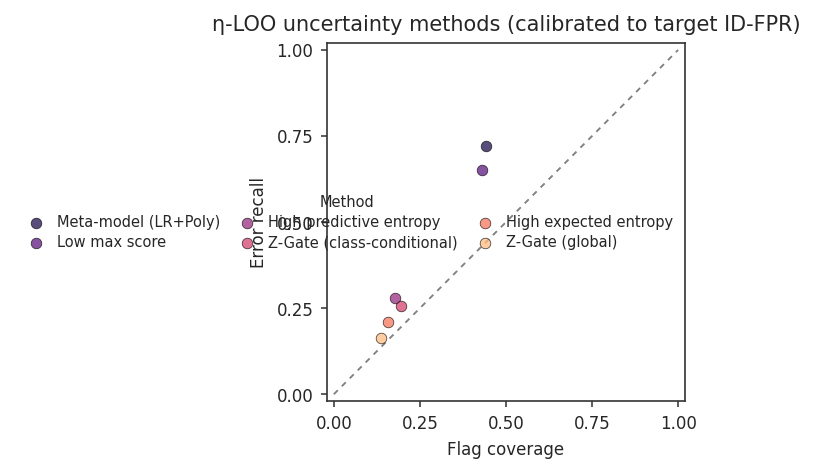

In [10]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from adjustText import adjust_text
    HAVE_ADJUST = True
except Exception:
    HAVE_ADJUST = False


# -----------------------------
# Global style: Nature-like
# -----------------------------
mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.2,
    "legend.title_fontsize": 7.2,
    "axes.linewidth": 0.9,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})


# -----------------------------
# Config
# -----------------------------
LABEL_MODE = "none"        # "none" | "repel" | "topk"
ROUND_DECIMALS = 5
EXPLODE_RADIUS = 0.006
POINT_SIZE = 26
POINT_ALPHA = 0.75
EDGE_LW = 0.35

TITLE = "η-LOO uncertainty methods (calibrated to target ID-FPR)"
XLAB = "Flag coverage"
YLAB = "Error recall"


# -----------------------------
# Color palette (restrained)
# -----------------------------
methods = list(overall_summary["Method"].astype(str))
palette = sns.color_palette("magma", n_colors=len(methods))
color_map = {m: palette[i] for i, m in enumerate(methods)}


# -----------------------------
# Explode exact duplicates only
# -----------------------------
tmp = overall_summary.copy()
tmp["_x0"] = tmp["coverage"].round(ROUND_DECIMALS)
tmp["_y0"] = tmp["err_recall"].round(ROUND_DECIMALS)

groups = {}
for idx, r in tmp.iterrows():
    key = (float(r["_x0"]), float(r["_y0"]))
    groups.setdefault(key, []).append(idx)

offsets = {}
for key, idxs in groups.items():
    k = len(idxs)
    if k == 1:
        offsets[idxs[0]] = (0.0, 0.0)
    else:
        angles = np.linspace(0, 2*np.pi, k, endpoint=False)
        for j, idx in enumerate(idxs):
            offsets[idx] = (
                EXPLODE_RADIUS * np.cos(angles[j]),
                EXPLODE_RADIUS * np.sin(angles[j])
            )


# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(3.35, 3.1))

# Random baseline (kept subtle)
ax.plot(
    [0, 1], [0, 1],
    ls=(0, (3, 3)),
    color="0.5",
    lw=0.9,
    zorder=1,
)

handles, labels = [], []
texts = []

for idx, row in overall_summary.iterrows():
    m = str(row["Method"])
    dx, dy = offsets.get(idx, (0.0, 0.0))

    x = float(np.clip(row["coverage"] + dx, 0, 1))
    y = float(np.clip(row["err_recall"] + dy, 0, 1))

    sc = ax.scatter(
        x, y,
        s=POINT_SIZE,
        color=color_map[m],
        alpha=POINT_ALPHA,
        edgecolor="black",
        linewidth=EDGE_LW,
        zorder=3
    )

    handles.append(sc)
    labels.append(m)

    if LABEL_MODE == "repel":
        texts.append(ax.text(x, y, m, fontsize=7.0))


if LABEL_MODE == "repel" and HAVE_ADJUST and texts:
    adjust_text(
        texts,
        ax=ax,
        expand_points=(1.15, 1.2),
        expand_text=(1.05, 1.1),
        arrowprops=dict(arrowstyle="-", color="0.6", lw=0.6),
    )


# -----------------------------
# Axes formatting
# -----------------------------
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(XLAB)
ax.set_ylabel(YLAB)
ax.set_title(TITLE, pad=6)

ticks = [0.0, 0.25, 0.5, 0.75, 1.0]
ax.set_xticks(ticks)
ax.set_yticks(ticks)

# Full black box (all spines on)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.9)
    spine.set_color("black")

# No grid, no reference lines
ax.grid(False)


# -----------------------------
# Legend: inside, bottom-right, 2 columns
# -----------------------------
leg = ax.legend(
    handles,
    labels,
    title="Method",
    ncol=3,
    loc="best",
    frameon=False,
    handletextpad=0.4,
    columnspacing=0.8,
    labelspacing=0.35,
    borderaxespad=0.4,
)
pdf_path = OUT / "coverage_vs_recall_eta.pdf"
save_figure(fig, pdf_path, bbox_inches="tight")
plt.show()



## Outputs
- `analysis_exports/uncertainty_estimator/eta_loo_per_compound_metrics.csv`: per-compound, per-split coverage/recall/precision/F1 for each method.
- `analysis_exports/uncertainty_estimator/eta_loo_overall_summary.csv`: overall concatenated performance across compounds.
- `images/figure5/coverage_vs_recall_eta.png`: coverage vs error-recall scatter (η-LOO).
- `images/figure5/precision_recall_f1_eta.png`: grouped precision/recall/F1 bars.

Notes on fairness:
- For each compound, training excludes that compound’s LOO+LOSO rows.
- Baseline thresholds, gates, and meta thresholds are all calibrated to the same target ID-FPR on training LOO-correct (higher score = riskier).
- Meta-model trains on remaining LOO+LOSO, but calibration for ID-FPR uses training LOO-correct only; evaluation is on the held-out compound’s LOO+LOSO.
- Progress bars added for loading pkls/npz and looping over compounds.



## Deployment-ready meta-model export
Train on all LOO+LOSO (so the model sees both confident and uncertain regimes), calibrate threshold on LOO-correct to meet the target ID-FPR, and export to `models/uncertainty_estimator/` for application use.


In [11]:
from joblib import dump

DEPLOY_DIR = Path("models/uncertainty_estimator"); DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

deploy_feats = [c for c in META_FEATS_ALL if c in tbl_loo.columns and c in tbl_loso.columns]

L_dep = tbl_loo.copy();  L_dep["dataset"] = "LOO";  L_dep["error"] = 1 - L_dep["correct"].astype(int)
S_dep = tbl_loso.copy(); S_dep["dataset"] = "LOSO"; S_dep["error"] = 1 - S_dep["correct"].astype(int)
D_dep = pd.concat([L_dep, S_dep], ignore_index=True)
D_dep = to_risk_space(D_dep)

pipe = make_pipeline(
    StandardScaler(with_mean=True, with_std=True),
    PolynomialFeatures(degree=2, include_bias=False),
    LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced", solver="lbfgs", random_state=RANDOM_STATE)
)
clf_deploy = CalibratedClassifierCV(pipe, method="sigmoid", cv=3)
clf_deploy.fit(D_dep[deploy_feats].fillna(0.0).values, D_dep["error"].values)
D_dep["p_error"] = clf_deploy.predict_proba(D_dep[deploy_feats].fillna(0.0).values)[:,1]

loo_corr_dep = D_dep[(D_dep["dataset"]=="LOO") & (D_dep["error"]==0)]
meta_thr_dep = float(np.nanpercentile(loo_corr_dep["p_error"], 100*(1.0 - TARGET_ID_FPR))) if len(loo_corr_dep)>=5 else 0.5

model_path = DEPLOY_DIR / "meta_model.joblib"
artifact_path = DEPLOY_DIR / "meta_artifact.json"

dump(clf_deploy, model_path)
artifact = {
    "feature_order": list(deploy_feats),
    "meta_threshold": meta_thr_dep,
    "target_id_fpr": float(TARGET_ID_FPR),
    "random_state": int(RANDOM_STATE),
    "preprocess": {
        "negate": ["PredScore", "Margin"],
        "fillna_value": 0.0
    }
}
with open(artifact_path, "w") as f:
    json.dump(artifact, f, indent=2)

print(f"[deploy] Saved meta model -> {model_path}")
print(f"[deploy] Saved artifact   -> {artifact_path}")
print(f"[deploy] Calibrated threshold (LOO-correct, target ID-FPR={TARGET_ID_FPR}): {meta_thr_dep:.3f}")


[deploy] Saved meta model -> models/uncertainty_estimator/meta_model.joblib
[deploy] Saved artifact   -> models/uncertainty_estimator/meta_artifact.json
[deploy] Calibrated threshold (LOO-correct, target ID-FPR=0.1): 0.469


## Statistical comparison (Walters-style repeated-measures workflow)
Use paired per-compound comparisons after removing redundant composite OR methods from panel-c analysis.
- Primary metric: `err_recall` (LOO+LOSO combined per compound).
- Omnibus test: repeated-measures ANOVA when available; rank-based fallback otherwise.
- Pairwise: Tukey-style studentized-range p-values when available; normal-approx fallback otherwise.
- Multiplicity correction: Holm (FWER control).
- Effect size: Cliff's delta with bootstrap CIs.


In [12]:
import itertools, math
import numpy as np
import pandas as pd

# --- methods shown in panel c ---
agg = (
    per_comp_df
      .assign(tp=lambda d: d["err_recall"] * d["n_err"])
      .groupby(["CompoundID", "Method"], as_index=False)
      .agg(
          tp_sum=("tp", "sum"),
          n_err_sum=("n_err", "sum"),
          coverage_mean=("coverage", "mean"),
          precision_mean=("precision", "mean"),
      )
      .assign(err_recall=lambda d: np.where(d["n_err_sum"] > 0, d["tp_sum"] / d["n_err_sum"], np.nan))
)[["CompoundID", "Method", "err_recall", "coverage_mean", "precision_mean", "n_err_sum"]]

primary_metric = "err_recall"
wide = agg.pivot(index="CompoundID", columns="Method", values=primary_metric)
wide_clean = wide.dropna(axis=0, how="any")

methods = wide_clean.columns.tolist()
N = len(wide_clean)
k = len(methods)

if N < 3 or k < 3:
    raise ValueError(f"Need >=3 compounds and >=3 methods; got compounds={N}, methods={k}")

print(f"Primary metric='{primary_metric}', compounds with complete data: {N}, methods: {methods}")


def holm_adjust(pvals):
    pvals = np.asarray(pvals, dtype=float)
    m = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    adj_ranked = np.empty(m, dtype=float)
    prev = 0.0
    for i, p in enumerate(ranked):
        val = (m - i) * p
        if val < prev:
            val = prev
        prev = val
        adj_ranked[i] = min(val, 1.0)
    out = np.empty(m, dtype=float)
    out[order] = adj_ranked
    return out


# --- omnibus + pairwise branch ---
omnibus_method = "rank_fallback"
omnibus_stat = np.nan
omnibus_p = np.nan

pair_rows = []

HAVE_SCIPY = False
try:
    from scipy.stats import studentized_range, f, shapiro, friedmanchisquare
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False

if HAVE_SCIPY:
    X = wide_clean[methods].to_numpy(dtype=float)
    grand = X.mean()
    method_means = X.mean(axis=0)
    subj_means = X.mean(axis=1, keepdims=True)

    ss_total = ((X - grand) ** 2).sum()
    ss_method = N * ((method_means - grand) ** 2).sum()
    ss_subject = k * ((subj_means.squeeze() - grand) ** 2).sum()
    ss_error = ss_total - ss_method - ss_subject

    df_method = k - 1
    df_error = (k - 1) * (N - 1)
    ms_method = ss_method / df_method
    ms_error = ss_error / df_error if df_error > 0 else np.nan

    omnibus_stat = float(ms_method / ms_error) if np.isfinite(ms_error) and ms_error > 0 else np.nan
    omnibus_p = float(f.sf(omnibus_stat, df_method, df_error)) if np.isfinite(omnibus_stat) else np.nan
    omnibus_method = "RM-ANOVA"

    resid = X - method_means - subj_means + grand
    try:
        shapiro_stat, shapiro_p = shapiro(resid.ravel())
    except Exception:
        shapiro_stat, shapiro_p = np.nan, np.nan

    se = math.sqrt(2 * ms_error / N)
    qcrit = float(studentized_range.ppf(0.95, k, df_error))
    ci_half = (qcrit / math.sqrt(2)) * se

    for i, j in itertools.combinations(range(k), 2):
        mi, mj = methods[i], methods[j]
        diff = float(method_means[i] - method_means[j])
        q = abs(diff) / se if se > 0 else np.nan
        p_raw = float(studentized_range.sf(q, k, df_error)) if np.isfinite(q) else np.nan
        pair_rows.append({
            "MethodA": mi,
            "MethodB": mj,
            "meandiff": diff,
            "lower": diff - ci_half,
            "upper": diff + ci_half,
            "q_stat": q,
            "p_raw": p_raw,
            "rank_diff": np.nan,
        })
else:
    # Rank-based fallback (works without scipy)
    ranks = wide_clean.rank(axis=1, method="average", ascending=False)
    Rbar = ranks.mean(axis=0)

    try:
        friedman_stat, friedman_p = friedmanchisquare(*[wide_clean[c].values for c in methods])
        omnibus_method = "Friedman"
        omnibus_stat = float(friedman_stat)
        omnibus_p = float(friedman_p)
    except Exception:
        omnibus_method = "Conover-normal-approx"
        omnibus_stat, omnibus_p = np.nan, np.nan

    def norm_sf(z):
        return 0.5 * math.erfc(z / math.sqrt(2))

    for i, j in itertools.combinations(range(k), 2):
        mi, mj = methods[i], methods[j]
        rank_diff = float(Rbar[mi] - Rbar[mj])
        z = abs(rank_diff) / math.sqrt(k * (k + 1) / (6 * N)) if N > 0 else np.nan
        p_raw = 2 * norm_sf(abs(z)) if np.isfinite(z) else np.nan
        pair_rows.append({
            "MethodA": mi,
            "MethodB": mj,
            "meandiff": float(wide_clean[mi].mean() - wide_clean[mj].mean()),
            "lower": np.nan,
            "upper": np.nan,
            "q_stat": z,
            "p_raw": p_raw,
            "rank_diff": rank_diff,
        })

pair_df = pd.DataFrame(pair_rows)
pair_df["p_adj_Holm"] = holm_adjust(pair_df["p_raw"].values)
# Keep legacy column name for downstream compatibility
pair_df["p_adj_BH"] = pair_df["p_adj_Holm"]
pair_df["signif_Holm_5%"] = pair_df["p_adj_Holm"] <= 0.05
pair_df["signif_BH_5%"] = pair_df["signif_Holm_5%"]
pair_df["correction_method"] = "Holm"
pair_df["primary_metric"] = primary_metric
pair_df["omnibus_method"] = omnibus_method
pair_df["omnibus_stat"] = omnibus_stat
pair_df["omnibus_p"] = omnibus_p
pair_df["n_compounds"] = N
pair_df["n_methods"] = k

# --- effect sizes: Cliff's delta with bootstrap CI ---
RNG = np.random.default_rng(42)
N_BOOT = 5000


def cliffs_delta(x, y):
    d = y - x
    wins = int((d > 0).sum())
    ties = int((d == 0).sum())
    losses = int((d < 0).sum())
    n = len(d)
    return (wins - losses) / n, wins, ties, losses


def cliffs_delta_boot(x, y, n_boot=N_BOOT):
    x = np.asarray(x)
    y = np.asarray(y)
    n = len(x)
    idx = np.arange(n)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        s = RNG.choice(idx, size=n, replace=True)
        vals[b] = cliffs_delta(x[s], y[s])[0]
    return np.quantile(vals, [0.025, 0.975])


cd_rows = []
for i, j in itertools.combinations(range(k), 2):
    mi, mj = methods[i], methods[j]
    dfp = wide_clean[[mi, mj]].dropna()
    if len(dfp) < 5:
        continue
    delta, wins, ties, losses = cliffs_delta(dfp[mi].values, dfp[mj].values)
    dlo, dhi = cliffs_delta_boot(dfp[mi].values, dfp[mj].values)
    cd_rows.append({
        "MethodA": mi,
        "MethodB": mj,
        "cliffs_delta": delta,
        "delta_ci_low": float(dlo),
        "delta_ci_high": float(dhi),
        "wins": wins,
        "ties": ties,
        "losses": losses,
        "n": len(dfp),
    })

cd_df = pd.DataFrame(cd_rows)
stats_df = pair_df.merge(cd_df, on=["MethodA", "MethodB"], how="left")

# Legacy filename kept for figure5_combined compatibility
stats_out = OUT / "eta_loo_pairwise_stats_BH.csv"
stats_df.to_csv(stats_out, index=False)

# Explicit Holm-named copy
stats_out_holm = OUT / "eta_loo_pairwise_stats_Holm.csv"
stats_df.to_csv(stats_out_holm, index=False)

summary_out = OUT / "eta_loo_omnibus_summary.txt"
with open(summary_out, "w") as f:
    f.write(f"primary_metric: {primary_metric}\n")
    f.write(f"methods_used: {methods}\n")
    f.write(f"n_compounds: {N}\n")
    f.write(f"omnibus_method: {omnibus_method}\n")
    f.write(f"omnibus_stat: {omnibus_stat}\n")
    f.write(f"omnibus_p: {omnibus_p}\n")
print("Saved pairwise stats ->", stats_out)
print("Saved pairwise stats (Holm alias) ->", stats_out_holm)
print("Saved omnibus summary ->", summary_out)

stats_df.sort_values("p_adj_Holm").head()


Primary metric='err_recall', compounds with complete data: 39, methods: ['High expected entropy', 'High predictive entropy', 'Low max score', 'Meta-model (LR+Poly)', 'Z-Gate (class-conditional)', 'Z-Gate (global)']
Saved pairwise stats -> analysis_exports/uncertainty_estimator/eta_loo_pairwise_stats_BH.csv
Saved pairwise stats (Holm alias) -> analysis_exports/uncertainty_estimator/eta_loo_pairwise_stats_Holm.csv
Saved omnibus summary -> analysis_exports/uncertainty_estimator/eta_loo_omnibus_summary.txt


,MethodA,MethodB,meandiff,lower,upper,q_stat,p_raw,rank_diff,p_adj_Holm,p_adj_BH,...,omnibus_p,n_compounds,n_methods,cliffs_delta,delta_ci_low,delta_ci_high,wins,ties,losses,n
13,Meta-model (LR+Poly),Z-Gate (global),0.551282,0.276743,0.825821,5.781178,0.000898,NaN,0.013474,0.013474,...,1.860054e-11,39,6,-0.589744,-0.769231,-0.384615,3,10,26,39
2,High expected entropy,Meta-model (LR+Poly),-0.538462,-0.813000,-0.263923,5.646732,0.001293,NaN,0.018104,0.018104,...,1.860054e-11,39,6,0.538462,0.358974,0.717949,22,16,1,39
11,Low max score,Z-Gate (global),0.500000,0.225461,0.774539,5.243394,0.003684,NaN,0.047888,0.047888,...,1.860054e-11,39,6,-0.512821,-0.692308,-0.307692,2,15,22,39
1,High expected entropy,Low max score,-0.487179,-0.761718,-0.212641,5.108948,0.005139,NaN,0.061669,0.061669,...,1.860054e-11,39,6,0.461538,0.230769,0.692308,24,9,6,39
6,High predictive entropy,Meta-model (LR+Poly),-0.461538,-0.736077,-0.187000,4.840056,0.009755,NaN,0.107300,0.107300,...,1.860054e-11,39,6,0.461538,0.256410,0.641026,21,15,3,39


### Visualize pairwise stats (Holm-adjusted p-values and effect sizes)


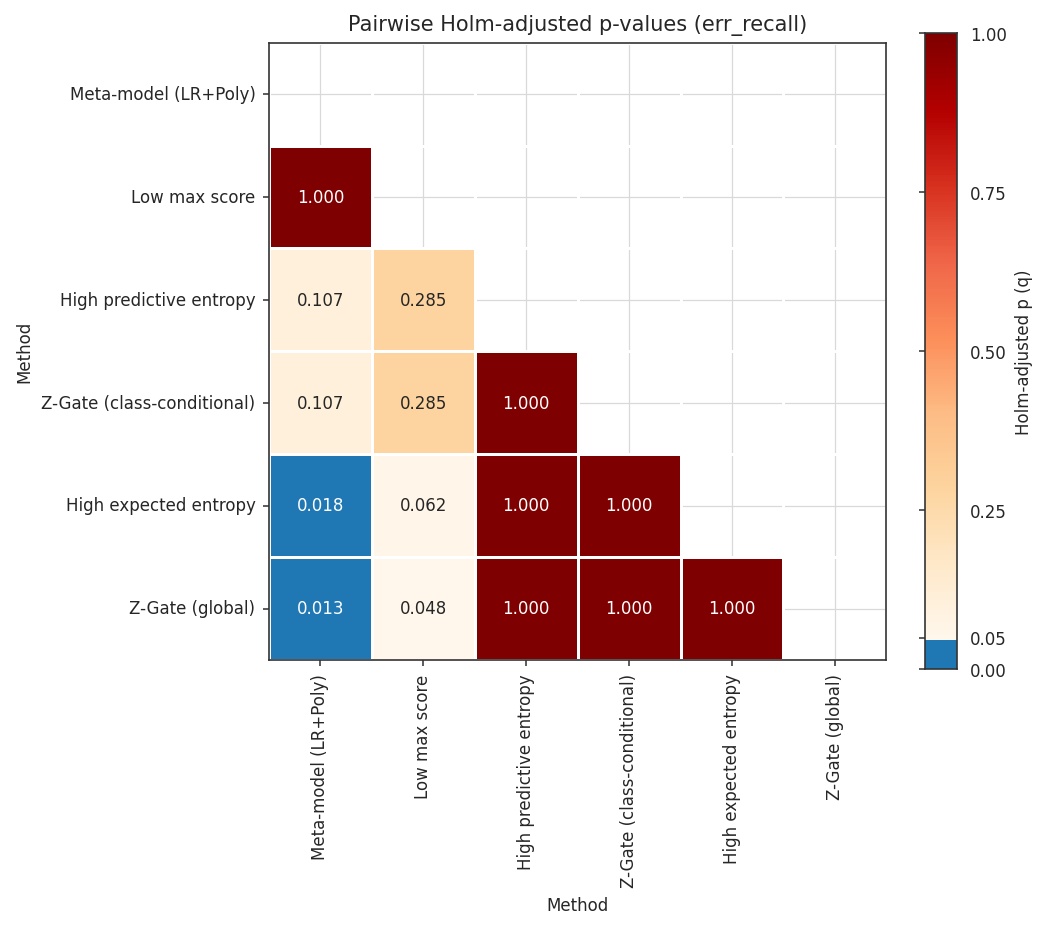

In [13]:
import seaborn as sns
from matplotlib import colors

# Pairwise Holm-adjusted p-value heatmap
alpha = 0.05
mat = pd.DataFrame(np.nan, index=methods, columns=methods)
for _, r in stats_df.iterrows():
    mat.loc[r.MethodA, r.MethodB] = r.p_adj_Holm
    mat.loc[r.MethodB, r.MethodA] = r.p_adj_Holm

# Use lower triangle only, ordered by mean primary metric (best -> worst)
order = wide_clean.mean(axis=0).sort_values(ascending=False).index.tolist()
mat = mat.loc[order, order].copy()
np.fill_diagonal(mat.values, np.nan)
mask_upper = np.triu(np.ones_like(mat, dtype=bool), k=1)

# Blue for significant (q<=0.05), red gradient for non-significant
n_total = 256
n_blue = max(1, int(np.floor(alpha * n_total)))
n_grad = n_total - n_blue
base = plt.get_cmap("OrRd", 256)
grad = base(np.linspace(0, 1, max(n_grad, 1)))
blue = np.tile(colors.to_rgba("#1f77b4"), (n_blue, 1))
cmap = colors.ListedColormap(np.vstack([blue, grad]))
norm = colors.Normalize(vmin=0.0, vmax=1.0)

fig, ax = plt.subplots(figsize=(7.0, 6.0))
hm = sns.heatmap(
    mat,
    mask=mask_upper,
    cmap=cmap,
    norm=norm,
    vmin=0.0,
    vmax=1.0,
    annot=True,
    fmt=".3f",
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar=True,
    cbar_kws={"label": "Holm-adjusted p (q)"},
    ax=ax,
)

cbar = hm.collections[0].colorbar
ticks = np.array([0.0, alpha, 0.25, 0.5, 0.75, 1.0])
ticks = np.unique(np.clip(ticks, 0, 1))
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t:.2f}" for t in ticks])

ax.set_title(f"Pairwise Holm-adjusted p-values ({primary_metric})")
ax.set_xlabel("Method")
ax.set_ylabel("Method")
plt.tight_layout()
save_figure(fig, OUT / "pairwise_pvals_heatmap.png", dpi=200)
plt.show()


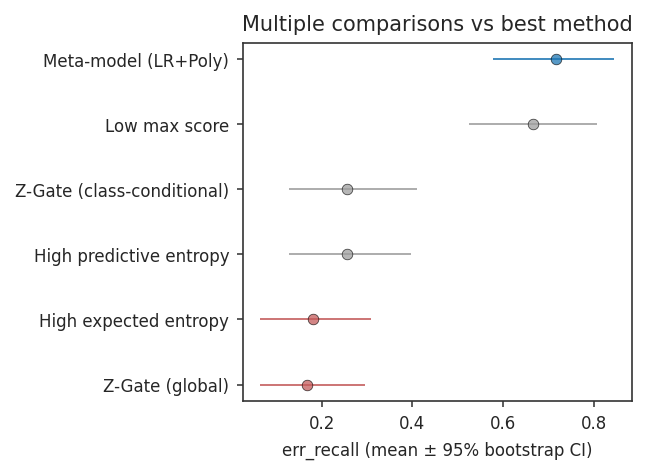

Best method by err_recall: Meta-model (LR+Poly)


In [14]:
# Paper-style CI plot on the primary metric (not deltas)
metric_for_best = primary_metric

# Use the same per-compound wide table (wide_clean) already built in the stats cell
N_BOOT = 5000
RNG = np.random.default_rng(42)

boot_rows = []
for m in methods:
    vals = wide_clean[m].values
    mean = np.nanmean(vals)
    boots = []
    for _ in range(N_BOOT):
        s = RNG.choice(vals, size=len(vals), replace=True)
        boots.append(np.nanmean(s))
    lo, hi = np.quantile(boots, [0.025, 0.975])
    boot_rows.append({"Method": m, "mean": mean, "ci_low": lo, "ci_high": hi})
ci_df = pd.DataFrame(boot_rows)

# Identify best method by mean metric
best_method = ci_df.sort_values("mean", ascending=False)["Method"].iloc[0]
best_row = ci_df[ci_df["Method"] == best_method].iloc[0]

# Map Holm significance vs best
sig_map = {}
for _, r in stats_df.iterrows():
    if (r.MethodA == best_method and r.MethodB in methods):
        sig_map[r.MethodB] = r.p_adj_Holm <= 0.05
    if (r.MethodB == best_method and r.MethodA in methods):
        sig_map[r.MethodA] = r.p_adj_Holm <= 0.05


def method_color(m):
    if m == best_method:
        return "#1f77b4"
    if sig_map.get(m, False):
        return "#c45c5c"
    return "#9e9e9e"


ci_df["color"] = ci_df["Method"].apply(method_color)
ci_df = ci_df.sort_values("mean")

fig, ax = plt.subplots(figsize=(3.35, 3.1))

for _, row in ci_df.iterrows():
    ax.hlines(row["Method"], row["ci_low"], row["ci_high"],
              colors=row["color"], linestyles="-", linewidth=0.8, zorder=2)
    ax.scatter(row["mean"], row["Method"],
               s=POINT_SIZE, color=row["color"], alpha=POINT_ALPHA,
               edgecolor="black", linewidth=EDGE_LW, zorder=3)

ax.set_xlabel(f"{metric_for_best} (mean ± 95% bootstrap CI)")
ax.set_ylabel("")
ax.set_title("Multiple comparisons vs best method", pad=6)
ax.tick_params(axis="both", which="major", width=0.8, length=3, labelsize=7.5)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.9)
    spine.set_color("black")
ax.grid(False)
pdf_path = OUT / "multiple_comparisons_primary_metric.pdf"
save_figure(fig, pdf_path, bbox_inches="tight")
plt.show()

print(f"Best method by {metric_for_best}: {best_method}")
